In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rc
rc('text', usetex=True)
import matplotlib.pylab as pylab
params = {'legend.fontsize': '14',
          'figure.figsize': (10,6),
          'axes.labelsize': 18,
          'axes.titlesize': 18,
          'xtick.labelsize': 14,
          'ytick.labelsize': 14}
pylab.rcParams.update(params)
from matplotlib import colors 
from matplotlib import colormaps as cm
import scipy.stats as st

In [2]:
data_200=dict(np.load('./LLZO/pure/MD_set/prediction_correlations_train_one_predict_one/MD_200_corr.npz',allow_pickle=True))
data_300=dict(np.load('./LLZO/pure/MD_set/prediction_correlations_train_one_predict_one/MD_300_corr.npz',allow_pickle=True))
data_400=dict(np.load('./LLZO/pure/MD_set/prediction_correlations_train_one_predict_one/MD_400_corr.npz',allow_pickle=True))
data_500=dict(np.load('./LLZO/pure/MD_set/prediction_correlations_train_one_predict_one/MD_500_corr.npz',allow_pickle=True))
data_600=dict(np.load('./LLZO/pure/MD_set/prediction_correlations_train_one_predict_one/MD_600_corr.npz',allow_pickle=True))
data_700=dict(np.load('./LLZO/pure/MD_set/prediction_correlations_train_one_predict_one/MD_700_corr.npz',allow_pickle=True))

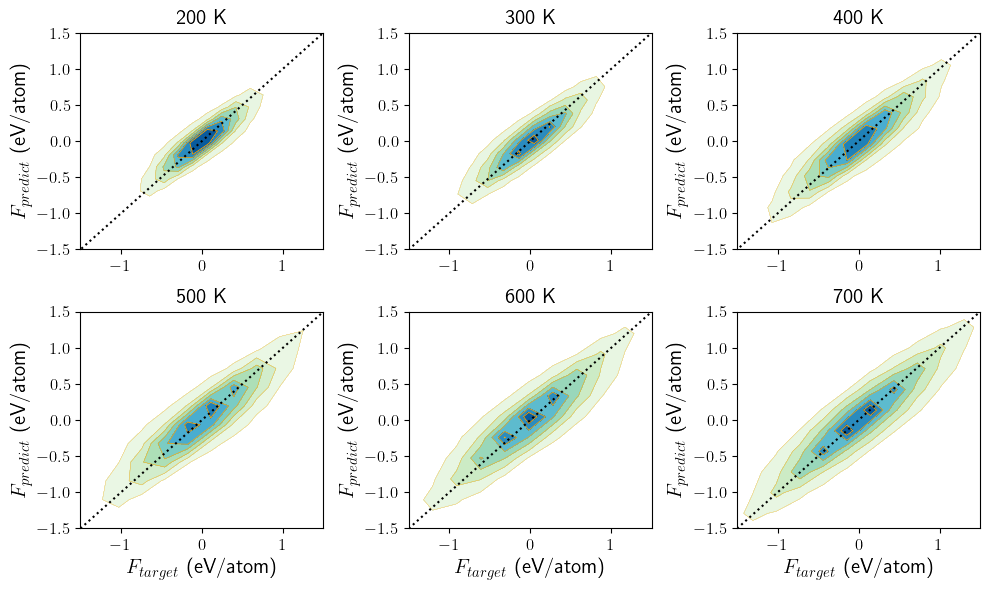

In [9]:
target='force'

if target == 'energy':
    key='E'
elif target == 'force':
    key='F'

temps=range(200,800,100)
for counter,d in enumerate([data_200,data_300,data_400,data_500,data_600,data_700]):
    
    min_x=100000
    max_x=-100000
    min_y=1000000
    max_y=-100000
    
    x=dict(enumerate(d['targets'].flatten()))[0][key].flatten()
    y=dict(enumerate(d['predictions'].flatten()))[0][key].flatten()
    
    min_x=min([min_x,min(x)])
    max_x=max([max_x,max(x)])
    min_y=min([min_y,min(y)])
    max_y=max([max_y,max(y)])
    
    xx, yy = np.mgrid[min(x)-1:max(x)+1:50j, min(y)-1:max(y)+1:50j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    values = np.vstack([x,y])
    kernel = st.gaussian_kde(values)
    f = np.reshape(kernel(positions).T, xx.shape)

    m = np.amax(f)
    step = m/7.0
    levels = np.arange(0.0, m, step) + step
    
    plt.subplot(2,3,counter+1)
    plt.contourf(xx, yy, f, levels, cmap=cm.get_cmap('GnBu'))
    plt.contour(xx, yy, f, levels, colors='orange',linewidths=[0.2+0.08*i for i in range(len(levels))])
    
    plt.plot([min_x,max_x],[min_x,max_x],'k:')
    if target == 'energy':
        plt.xlim([min_x,max_x])
        plt.ylim([min_x,max_x])
    elif target == 'force':
        plt.xlim([-1.5,1.5])
        plt.ylim([-1.5,1.5])
    
    plt.title(str(temps[counter])+' K')
    
    if counter not in [0,1,2]:
        if target == 'energy':
            plt.xlabel("$E_{target}$ (eV)")
        elif target == 'force':
            plt.xlabel("$F_{target}$ (eV/atom)")
    if target == 'energy':
        plt.ylabel("$E_{predict}$ (eV)")
    elif target == 'force':
        plt.ylabel("$F_{predict}$ (eV/atom)")

plt.tight_layout()
if target == 'force':
    plt.savefig('force_correlations_model_trained_on_one.pdf')
elif target == 'energy':
    plt.savefig('energy_correlations_model_trained_on_one.pdf')

plt.show()

In [3]:
data_2_2=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_200_test_200_geo_opt_corr.npz',allow_pickle=True))
data_2_3=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_200_test_300_geo_opt_corr.npz',allow_pickle=True))
data_2_4=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_200_test_400_geo_opt_corr.npz',allow_pickle=True))

data_3_2=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_300_test_200_geo_opt_corr.npz',allow_pickle=True))
data_3_3=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_300_test_300_geo_opt_corr.npz',allow_pickle=True))
data_3_4=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_300_test_400_geo_opt_corr.npz',allow_pickle=True))

data_4_2=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_400_test_200_geo_opt_corr.npz',allow_pickle=True))
data_4_3=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_400_test_300_geo_opt_corr.npz',allow_pickle=True))
data_4_4=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_400_test_400_geo_opt_corr.npz',allow_pickle=True))

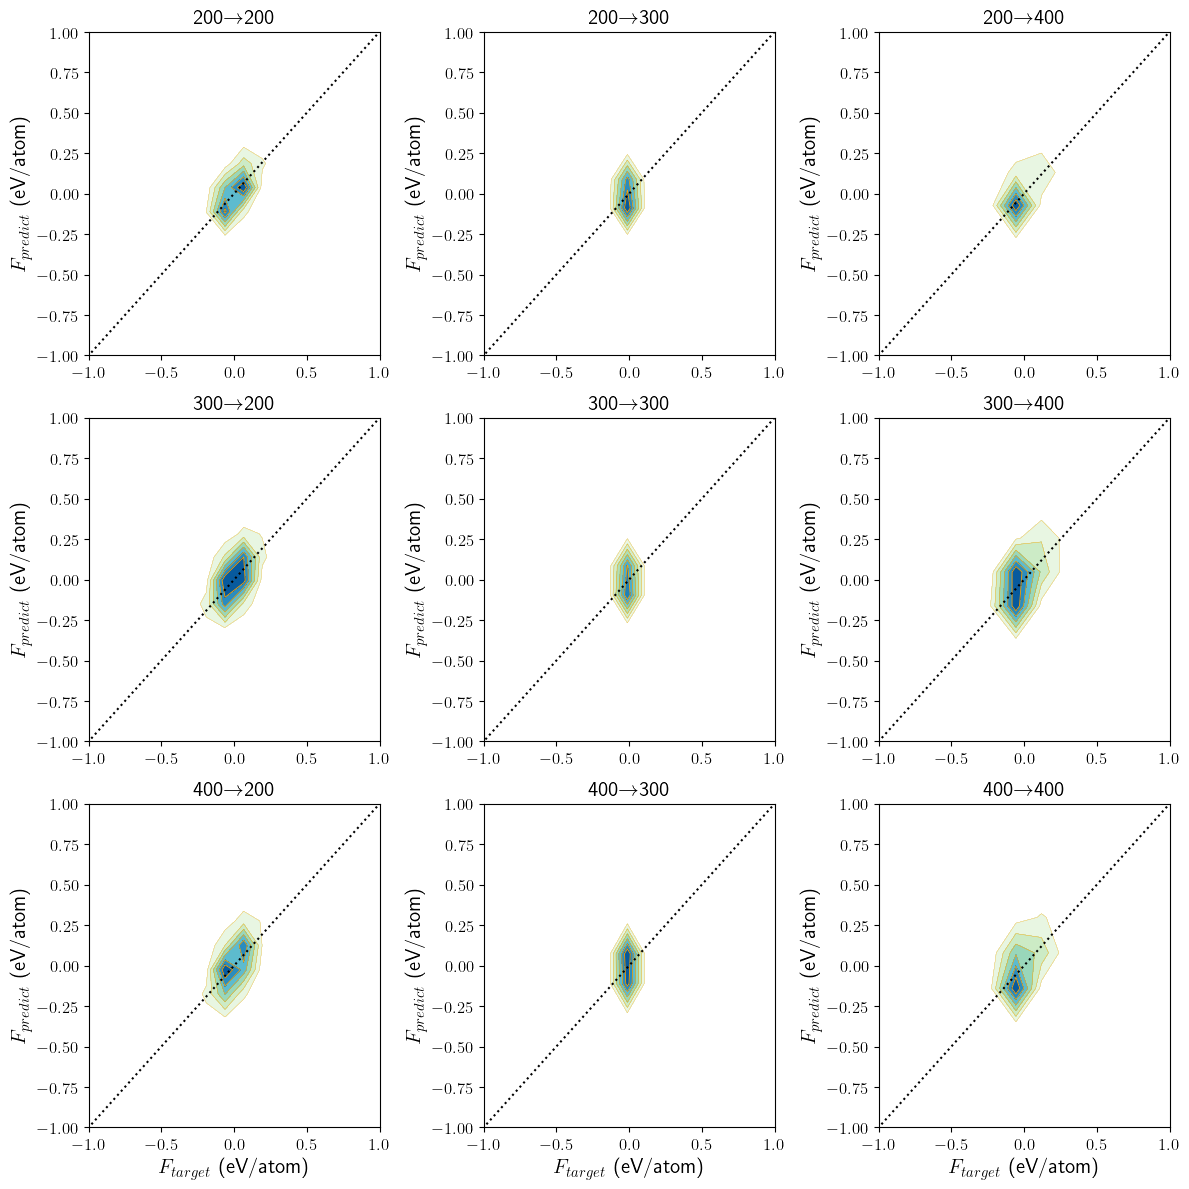

In [12]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

target='force'

if target == 'energy':
    key='E'
elif target == 'force':
    key='F'
    
plt.figure(figsize=(12,12))

temps=[200,300,400]
titles = []
for i in range(3):
    for j in range(3):
        title = str(temps[i])+'$\\to$'+str(temps[j])
        titles.append(title)

for counter,d in enumerate([data_2_2,data_2_3,data_2_4,data_3_2,data_3_3,data_3_4,data_4_2,data_4_3,data_4_4]):
    
    min_x=100000
    max_x=-100000
    min_y=1000000
    max_y=-100000
    
    x=dict(enumerate(d['targets'].flatten()))[0][key].flatten()
    y=dict(enumerate(d['predictions'].flatten()))[0][key].flatten()
    
    min_x=min([min_x,min(x)])
    max_x=max([max_x,max(x)])
    min_y=min([min_y,min(y)])
    max_y=max([max_y,max(y)])
    
    xx, yy = np.mgrid[min(x)-1:max(x)+1:50j, min(y)-1:max(y)+3:50j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    values = np.vstack([x,y])
    kernel = st.gaussian_kde(values)
    f = np.reshape(kernel(positions).T, xx.shape)

    m = np.amax(f)
    step = m/7.0
    levels = np.arange(0.0, m, step) + step
    
    ax=plt.subplot(3,3,counter+1)
    ax.contourf(xx, yy, f, levels, cmap=cm.get_cmap('GnBu'))
    ax.contour(xx, yy, f, levels, colors='orange',linewidths=[0.2+0.08*i for i in range(len(levels))])
    
    ax.plot([min_x,max_x],[min_x,max_x],'k:')
    if target == 'energy':
        ax.set_xlim([min(x)-1,min(x)+1])
        ax.set_ylim([min(y)-1,min(y)+3])
    elif target == 'force':
        ax.set_xlim([-1,1])
        ax.set_ylim([-1,1])
        
    if counter not in [0,1,2,3,4,5]:
        if target == 'energy':
            ax.set_xlabel("$E_{target}$ (eV)")
        elif target == 'force':
            ax.set_xlabel("$F_{target}$ (eV/atom)")
    if target == 'energy':
        ax.set_ylabel("$E_{predict}$ (eV)")
    elif target == 'force':
        ax.set_ylabel("$F_{predict}$ (eV/atom)")
    
    ax.set_title(titles[counter])

plt.tight_layout()

if target == 'force':
    plt.savefig('force_correlations_model_transfer_geopt.pdf')
elif target == 'energy':
    plt.savefig('energy_correlations_model_transfer_geopt.pdf')
plt.show()

In [ ]:
plt.figure(figsize=(12,4))

data_2=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_warmup_test_200_geo_opt_corr.npz',allow_pickle=True))
data_3=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_warmup_test_300_geo_opt_corr.npz',allow_pickle=True))
data_4=dict(np.load('./LLZO/pure/MD_set/transfer_learnings_geo_opt_from_md/MD_tr_warmup_test_400_geo_opt_corr.npz',allow_pickle=True))

target='force'

if target == 'energy':
    key='E'
elif target == 'force':
    key='F'
    
titles={0:'200 K', 1:'300 K', 2:'400 K'}
for counter,d in enumerate([data_2,data_3,data_4]):
    min_x=100000
    max_x=-100000
    min_y=1000000
    max_y=-100000
    
    x=dict(enumerate(d['targets'].flatten()))[0][key].flatten()
    y=dict(enumerate(d['predictions'].flatten()))[0][key].flatten()
    
    min_x=min([min_x,min(x)])
    max_x=max([max_x,max(x)])
    min_y=min([min_y,min(y)])
    max_y=max([max_y,max(y)])
    
    xx, yy = np.mgrid[min(x)-1:max(x)+1:50j, min(y)-1:max(y)+3:50j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    values = np.vstack([x,y])
    kernel = st.gaussian_kde(values)
    f = np.reshape(kernel(positions).T, xx.shape)

    m = np.amax(f)
    step = m/7.0
    levels = np.arange(0.0, m, step) + step
    
    ax=plt.subplot(1,3,counter+1)
    ax.contourf(xx, yy, f, levels, cmap=cm.get_cmap('GnBu'))
    ax.contour(xx, yy, f, levels, colors='orange',linewidths=[0.2+0.08*i for i in range(len(levels))])
    
    ax.plot([min_x,max_x],[min_x,max_x],'k:')
    if target == 'energy':
        ax.set_xlim([min(x)-1,min(x)+1])
        ax.set_ylim([min(y)-1,min(y)+1])
    elif target == 'force':
        ax.set_xlim([-1,1])
        ax.set_ylim([-1,1])
        
    
    if target == 'energy':
        ax.set_xlabel("$E_{target}$ (eV)")
    elif target == 'force':
        ax.set_xlabel("$F_{target}$ (eV/atom)")
        
    if target == 'energy':
        ax.set_ylabel("$E_{predict}$ (eV)")
    elif target == 'force':
        ax.set_ylabel("$F_{predict}$ (eV/atom)")
    
    ax.set_title(titles[counter])

plt.tight_layout()

In [33]:
def scatter_hist(x, y, ax, ax_histx, ax_histy):
    # no labels
    ax_histx.tick_params(axis="x", labelbottom=False)
    ax_histy.tick_params(axis="y", labelleft=False)

    # the scatter plot:
    ax.scatter(x, y, alpha=0.5,c='#2C7873',s=2)

    # now determine nice limits by hand:
    #binwidth = 1
    #xymax = max(np.max(np.abs(x)), np.max(np.abs(y)))
    #lim = (int(xymax/binwidth) + 1) * binwidth

    #bins = np.arange(-lim, lim + binwidth, binwidth)
    #ax_histx.hist(x, bins=bins,alpha=0.8,color='#336B87')
    #ax_histy.hist(y, bins=bins, orientation='horizontal',alpha=0.8,color='#336B87')

    kernel = st.gaussian_kde(x)
    _x=np.arange(min(x)-1,max(x)+1,0.01)
    ax_histx.plot(_x,kernel(_x),'-',c='#2C7873')

    kernel = st.gaussian_kde(y)
    _x=np.arange(min(y)-1,max(y)+1,0.01)
    ax_histy.plot(kernel(_x),_x,'-',c='#2C7873')

def hist_compare(x, y,title=None):
    plt.figure(figsize=(6,5))
    kernel = st.gaussian_kde(x)
    _x=np.arange(min(x)-1,max(x)+1,0.01)
    plt.plot(_x,kernel(_x),'-',c='k',lw=3,label='Target distribution')

    kernel = st.gaussian_kde(y)
    _x=np.arange(min(y)-1,max(y)+1,0.01)
    plt.plot(_x,kernel(_x),'--',c='k',lw=3,label='Predicted distribution')
    plt.xlabel('Energy (eV)')
    plt.ylabel('$p(E)$')
    plt.xlim([-1505.7,-1504.3])
    plt.title(title)
    plt.legend()

MSE is : 0.01928505756314149


/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_11157/3323282471.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


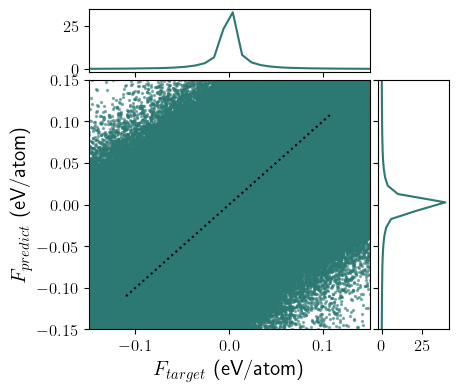

In [35]:
target='force'

if target == 'energy':
    key='E'
elif target == 'force':
    key='F'
    
d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_corr_large_nn_high_wf.npz',allow_pickle=True))
#d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_last_frame_corr.npz',allow_pickle=True))
min_x=100000
max_x=-100000
min_y=1000000
max_y=-100000
    
x=dict(enumerate(d['targets'].flatten()))[0][key].flatten()
y=dict(enumerate(d['predictions'].flatten()))[0][key].flatten()

mse=np.sqrt(np.square(x-y).mean())
print("MSE is :", mse)

min_x=min([min_x,min(x)])
max_x=max([max_x,max(x)])
min_y=min([min_y,min(y)])
max_y=max([max_y,max(y)])
xx, yy = np.mgrid[min(x)-1:max(x)+1:50j, min(y)-1:max(y)+3:50j]

if target == 'force':
    min_x = -0.01
    max_x = 0.01
    min_y = -0.01
    max_y = 0.01
    xx, yy = np.mgrid[min(x)-0.01:max(x)+0.01:50j, min(y)-0.01:max(y)+0.01:50j]


#positions = np.vstack([xx.ravel(), yy.ravel()])
#values = np.vstack([x,y])
#kernel = st.gaussian_kde(values)
#f = np.reshape(kernel(positions).T, xx.shape)

#m = np.amax(f)
#step = m/7.0
#levels = np.arange(0.0, m, step) + step

fig = plt.figure(figsize=(4.5,4))


#ax.contourf(xx, yy, f, levels, cmap=cm.get_cmap('GnBu'))
#ax.contour(xx, yy, f, levels, colors='orange',linewidths=[0.2+0.08*i for i in range(len(levels))])
gs = fig.add_gridspec(2, 2,  width_ratios=(4, 1), height_ratios=(1, 4),
                      left=0.1, right=0.9, bottom=0.1, top=0.9,
                      wspace=0.05, hspace=0.05)

#ax.plot(x,y,'.',alpha=0.5,c='#336B87')

ax = fig.add_subplot(gs[1, 0])
ax_histx = fig.add_subplot(gs[0, 0], sharex=ax)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)
# Draw the scatter plot and marginals.
scatter_hist(x, y, ax, ax_histx, ax_histy)

ax.plot([min_x-0.1,max_x+0.1],[min_x-0.1,max_x+0.1],'k:')
if target == 'energy':
    ax.set_xlim([min_x-0.1,max_x+0.1])
    ax.set_ylim([min_x-0.1,max_x+0.1])
elif target == 'force':
    ax.set_xlim([-0.15,0.15])
    ax.set_ylim([-0.15,0.15])
        
    
if target == 'energy':
    ax.set_xlabel("$E_{target}$ (eV)")
elif target == 'force':
    ax.set_xlabel("$F_{target}$ (eV/atom)")
        
if target == 'energy':
    ax.set_ylabel("$E_{predict}$ (eV)")
elif target == 'force':
    ax.set_ylabel("$F_{predict}$ (eV/atom)")

plt.tight_layout()

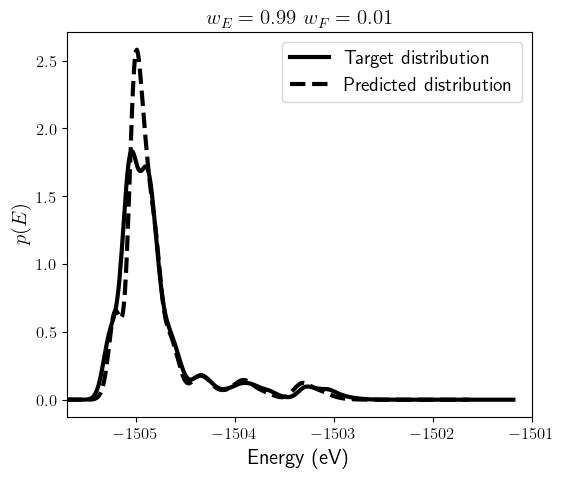

In [34]:
hist_compare(x,y,title="$w_{E}=0.99$"+' '+"$w_{F}=0.01$")
#plt.savefig('high_wf_distr.pdf')

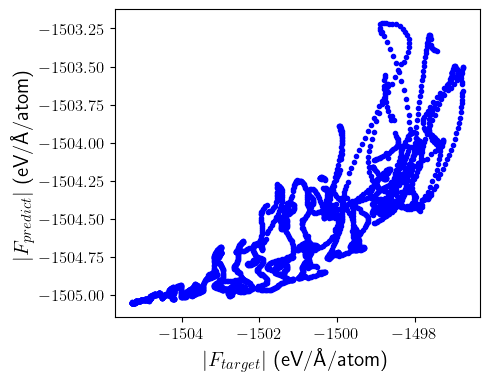

In [13]:
import matplotlib as mpl

target='energy'

if target == 'energy':
    key='E'
elif target == 'force':
    key='F'
    
d=dict(np.load('./LLZO/llzo_12_44/12_44_struc_2154640_evaluate.npz',allow_pickle=True))
#d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_last_frame_corr.npz',allow_pickle=True))
    
x=dict(enumerate(d['targets'].flatten()))[0][key].flatten()
y=dict(enumerate(d['predictions'].flatten()))[0][key].flatten()
#x=[abs(_x) for _x in x]
#y=[abs(_y) for _y in y]

fig = plt.figure(figsize=(4.7,4))
plt.plot(x,y,'b.')
#plt.plot([0,0.16],[0,0.16],'k--')
#plt.hist2d(x,y,bins=1000,norm=mpl.colors.LogNorm(),cmap=plt.cm.coolwarm,cmin = 100,alpha=0.9)

#plt.xlim([0,0.5])
#plt.ylim([0,0.1])

#plt.colorbar(label='Counts',format='%.0e')    
plt.ylabel("$\\vert F_{predict} \\vert$ (eV/$\\mbox{\AA}$/atom)")
plt.xlabel("$\\vert F_{target} \\vert$ (eV/$\\mbox{\AA}$/atom)")
plt.show()

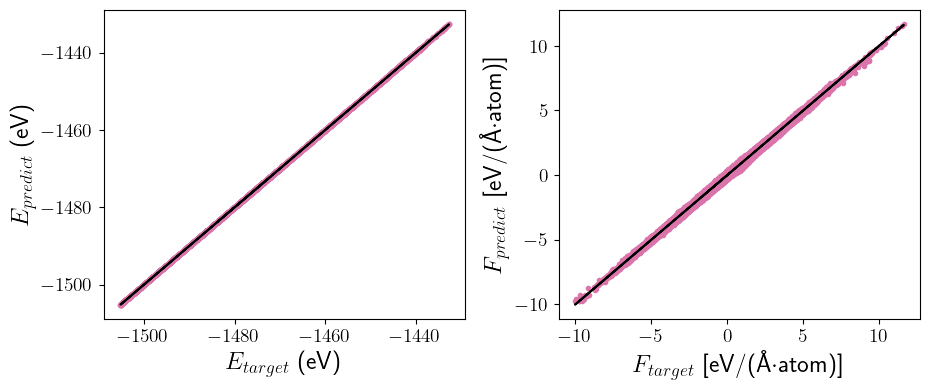

In [3]:
data=dict(np.load('./LLZO/llzo_12_44/all_data_warmup_MD_corr.npz',allow_pickle=True))

fig = plt.figure(figsize=(4.7*2,4))

plt.subplot(1,2,1)
key='E'
x=dict(enumerate(data['targets'].flatten()))[0][key].flatten()
y=dict(enumerate(data['predictions'].flatten()))[0][key].flatten()

plt.plot(x,y,'.',c='#DB74AB')
plt.plot(x,x,'k-')
plt.ylabel("$E_{predict}$ (eV)")
plt.xlabel("$E_{target}$ (eV)")

plt.subplot(1,2,2)
key='F'
x=dict(enumerate(data['targets'].flatten()))[0][key].flatten()
y=dict(enumerate(data['predictions'].flatten()))[0][key].flatten()
plt.plot(x,y,'.',c='#DB74AB')
plt.plot(x,x,'k-')
plt.ylabel("$F_{predict}$ [eV/($\\mbox{\AA}\cdot$atom)]")
plt.xlabel("$F_{target}$ [eV/($\\mbox{\AA}\cdot$atom)]")
plt.tight_layout()
plt.savefig('all_data_warmup_MD_correlation.tif')
plt.show()


223140
Energy MSE is 0.038495549409434754 eV
128528640
Force MSE is 0.01822321307859978 eV/A/atom


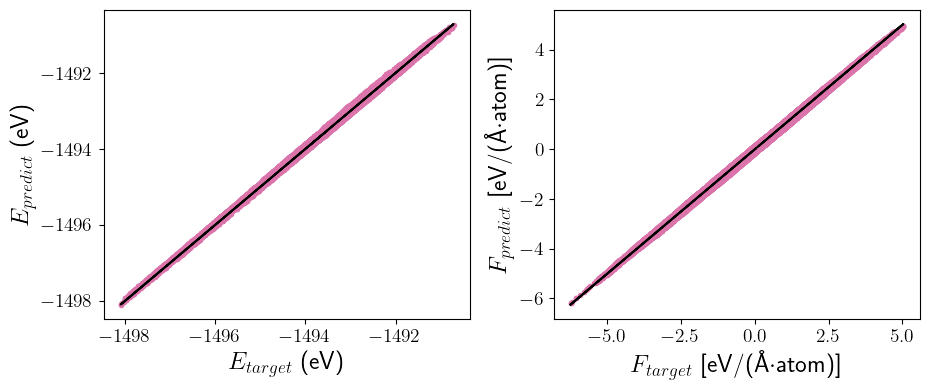

In [2]:
import glob
fig = plt.figure(figsize=(4.7*2,4))

all_data=glob.glob('./LLZO/llzo_12_44/MD_sets/*corr.npz')

x=np.array([])
y=np.array([])
key='E'
for d in all_data:
    data=dict(np.load(d,allow_pickle=True))

    _x=dict(enumerate(data['targets'].flatten()))[0][key].flatten()
    _y=dict(enumerate(data['predictions'].flatten()))[0][key].flatten()
    x=np.append(x,_x)
    y=np.append(y,_y)
    del _x
    del _y

print(len(x))
mse=np.abs(np.subtract(np.array(x), np.array(y))).mean()
print("Energy MSE is "+str(mse)+" eV")
plt.subplot(1,2,1)
plt.plot(x,y,'.',c='#DB74AB')
plt.plot(x,x,'k-')
plt.ylabel("$E_{predict}$ (eV)")
plt.xlabel("$E_{target}$ (eV)")

x=np.array([])
y=np.array([])
key='F'
for d in all_data:
    data=dict(np.load(d,allow_pickle=True))

    _x=dict(enumerate(data['targets'].flatten()))[0][key].flatten()
    _y=dict(enumerate(data['predictions'].flatten()))[0][key].flatten()
    x=np.append(x,_x)
    y=np.append(y,_y)
    del _x
    del _y

print(len(y))
mse=np.abs(np.subtract(np.array(x), np.array(y))).mean()
print("Force MSE is "+str(mse)+" eV/A/atom")
plt.subplot(1,2,2)
plt.plot(x,y,'.',c='#DB74AB')
plt.plot(x,x,'k-')
plt.ylabel("$F_{predict}$ [eV/($\\mbox{\AA}\cdot$atom)]")
plt.xlabel("$F_{target}$ [eV/($\\mbox{\AA}\cdot$atom)]")
plt.tight_layout()

plt.savefig('llzo_12_44_MD_testset_corr_correct_pbc.tif')
plt.show()
